# Cicero: cis-co-accessibility networks

Cicero (Pliner *et al.*, *Molecular Cell* 2018) predicts which pairs of accessible sites are
co-accessible in single-cell ATAC-seq data. Single cells are too sparse to correlate directly,
so Cicero

1. **aggregates** cells: each bin is a cell and its *k − 1* nearest neighbours in a 2-D embedding,
   with bins that overlap too much (≥ 90 % shared cells) discarded;
2. computes, inside overlapping 500 kb windows of the genome, the **covariance** of the sites
   across bins and regularises it with the **graphical lasso**, penalising pairs more the farther
   apart they are: `rho_ij = distance_parameter · (1 − (1 kb / d_ij)^s)`, `s = 0.75`;
3. **calibrates** `distance_parameter` on random windows so that almost no pair farther apart than
   250 kb stays connected;
4. **assembles** the regularised correlations of all windows into one table (`Peak1`, `Peak2`,
   `coaccess`), averaging pairs seen in two windows when their signs agree.

The table is what CellOracle's base-GRN step reads, and it feeds Cicero's CCANs (modules of
co-accessible sites) and gene-activity scores.

`epione.tl` contains a port of the R package (Monocle 3 branch, v1.3.9) that matches R on the
pre-registered gates in `tests/parity/cicero/MANIFEST.md`: same aggregation bins and sampled
windows (R's random-number generator is reproduced bit for bit), the same distance parameter,
co-accessibility values within 1e-15 of R and identical CCANs, on Cicero's example data and on a
16,787-cell heart multiome. Input is an AnnData with **cells in rows and peaks in columns**.

| R (cicero) | Python (`epione.tl`) |
|---|---|
| `make_atac_cds` | `make_atac_cds` |
| `make_cicero_cds` | `make_cicero_cds` |
| `estimate_distance_parameter` | `estimate_distance_parameter` |
| `generate_cicero_models` | `generate_cicero_models` |
| `assemble_connections` | `assemble_connections` |
| `run_cicero` | `run_cicero` |
| `generate_ccans`, `find_overlapping_ccans` | `generate_ccans`, `find_overlapping_ccans` |
| `annotate_cds_by_site`, `build_gene_activity_matrix`, `normalize_gene_activities` | same names |
| `aggregate_nearby_peaks`, `aggregate_by_cell_bin`, `compare_connections`, `find_overlapping_coordinates`, `df_for_coords` | same names |
| `glasso::glasso` | `glasso` |
| — | `cicero_connections_to_celloracle` |

## Part 1 — Cicero's example data

`cicero_data` is the example shipped with the R package: sci-ATAC-seq of human skeletal muscle
myoblasts, chromosome 18 only, 200 cells. The parity tests keep a copy, together with the UMAP
that monocle3 computed for it in R (Cicero aggregates on fixed reduced coordinates, so both sides
use the same ones).

In [1]:
import os, time
from pathlib import Path
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import anndata as ad
import epione as epi

ref = np.load(Path("../../../tests/parity/cicero/reference/F1_cicero_data_seed42.npz"))
m = sp.csc_matrix((ref["x_x"], ref["x_i"], ref["x_p"]), shape=tuple(ref["shape"]))   # peaks x cells
coo = m.tocoo()
triplets = pd.DataFrame({"peak": ref["peaks"][coo.row], "cell": ref["cells"][coo.col], "count": coo.data})
print(triplets.shape)
triplets.head()

(35137, 3)


,peak,cell,count
0,chr18_597174_597674,AGCGATAGAACGAATTCGGCGCAATGACCCTATCCT,1.0
1,chr18_685972_687566,AGCGATAGAACGAATTCGGCGCAATGACCCTATCCT,1.0
2,chr18_712676_713256,AGCGATAGAACGAATTCGGCGCAATGACCCTATCCT,1.0
3,chr18_808094_808525,AGCGATAGAACGAATTCGGCGCAATGACCCTATCCT,1.0
4,chr18_2303845_2304265,AGCGATAGAACGAATTCGGCGCAATGACCCTATCCT,1.0


### `make_atac_cds` — triplets to AnnData

```r
input_cds <- make_atac_cds(cicero_data, binarize = TRUE)
```
Sparse `(peak, cell, count)` rows become a cells × peaks AnnData. Peaks are ordered by chromosome
and start, as in R (this order matters later: glasso visits sites in this order).

In [2]:
atac = epi.tl.make_atac_cds(triplets, binarize=True)
atac.obsm["X_umap"] = pd.DataFrame(ref["coords"], index=ref["cells"]).loc[atac.obs_names].to_numpy()
print(atac)
atac.var.head(3)

AnnData object with n_obs × n_vars = 200 × 6146
    obs: 'cells', 'num_genes_expressed', 'Size_Factor'
    var: 'site_name', 'chr', 'bp1', 'bp2', 'num_cells_expressed'
    obsm: 'X_umap'


,site_name,chr,bp1,bp2,num_cells_expressed
chr18_10025_10225,chr18_10025_10225,18,10025.0,10225.0,5
chr18_10603_11103,chr18_10603_11103,18,10603.0,11103.0,1
chr18_11604_13986,chr18_11604_13986,18,11604.0,13986.0,9


### `make_cicero_cds` — aggregate similar cells

```r
set.seed(42)
cicero_cds <- make_cicero_cds(input_cds, reduced_coordinates = umap_coords)   # k = 50
```
`random_state=42` reproduces `set.seed(42)` immediately before the R call: the bins are drawn with
the same Mersenne-Twister stream as R. With 200 cells and k = 50 only a few bins survive, and
they overlap a lot — Cicero warns about it, as R does.

Overlap QC metrics:
Cells per bin: 50
Maximum shared cells bin-bin: 44
Mean shared cells bin-bin: 11.17
Median shared cells bin-bin: 0.5


(25, 6146) bins x peaks


/scratch/users/steorra/analysis/26_dynode-project/cicero_port/epione/epione/tl/_cicero.py:325: UserWarning: On average, more than 10% of cells are shared between paired bins.
  warnings.warn("On average, more than 10% of cells are shared between paired bins.")


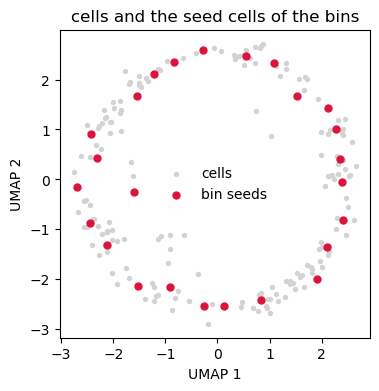

In [3]:
cicero = epi.tl.make_cicero_cds(atac, reduced_coordinates="X_umap", k=50, random_state=42)
print(cicero.shape, "bins x peaks")
seeds = cicero.uns["cicero"]["chosen"]
fig, ax = plt.subplots(figsize=(4, 4))
ax.scatter(*atac.obsm["X_umap"].T, s=8, c="lightgrey", label="cells")
ax.scatter(*atac.obsm["X_umap"][seeds].T, s=25, c="crimson", label="bin seeds")
ax.set(xlabel="UMAP 1", ylabel="UMAP 2", title="cells and the seed cells of the bins"); ax.legend(frameon=False)
plt.show()

### `estimate_distance_parameter` — calibrate the distance penalty

```r
set.seed(42)
distance_parameters <- estimate_distance_parameter(cicero_cds, sample_num = 100,
                                                   genomic_coords = sample_genome)
```
Random 500 kb windows are drawn (with replacement). In each, the smallest `distance_parameter` is
found by bisection such that at most 5 % of the pairs farther than 250 kb stay non-zero in the
glasso inverse. `genomic_coords` lists the chromosome lengths; only those chromosomes are scanned.
`n_jobs` runs the windows in threads with identical results.

100 windows in 7.3 s; mean = 0.640494


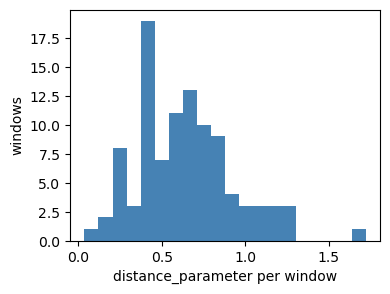

In [4]:
genome = pd.DataFrame({"chr": ref["genome_chr"], "length": ref["genome_len"]})
t0 = time.perf_counter()
dps = epi.tl.estimate_distance_parameter(cicero, genomic_coords=genome, random_state=42, n_jobs=8)
print(f"{len(dps)} windows in {time.perf_counter() - t0:.1f} s; mean = {dps.mean():.6f}")
plt.figure(figsize=(4, 3)); plt.hist(dps, bins=20, color="steelblue")
plt.xlabel("distance_parameter per window"); plt.ylabel("windows"); plt.show()

### `generate_cicero_models` — windowed graphical lasso

```r
cicero_out <- generate_cicero_models(cicero_cds, distance_parameter = mean(distance_parameters),
                                     genomic_coords = sample_genome)
```
One glasso fit per window (500 kb, step 250 kb). Windows with fewer than two or more than 200
sites are skipped with the same messages as R.

glasso                          283
Zero or one element in range     30
Name: count, dtype: int64


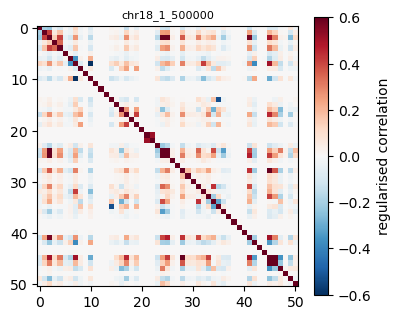

In [5]:
mean_dp = float(np.mean(dps))
models = epi.tl.generate_cicero_models(cicero, distance_parameter=mean_dp, genomic_coords=genome, n_jobs=8)
status = pd.Series(["glasso" if isinstance(v, epi.tl._cicero.CiceroModel) else v for v in models.values()])
print(status.value_counts())
name, mod = next((k, v) for k, v in models.items() if not isinstance(v, str) and len(v.peaks) > 40)
w = mod.w; cor = w / np.sqrt(np.outer(np.diag(w), np.diag(w)))
plt.figure(figsize=(4.2, 3.6)); plt.imshow(cor, cmap="RdBu_r", vmin=-0.6, vmax=0.6)
plt.colorbar(label="regularised correlation"); plt.title(name, fontsize=8); plt.show()

### `assemble_connections` — one co-accessibility table

```r
conns <- assemble_connections(cicero_out)
```
Each pair appears in both orientations; pairs seen in two windows get the mean when the signs
agree and `NaN` otherwise (R's `NA`).

Successful cicero models:  283
Other models: 
Zero or one element in range    30
Models with errors:  0


(543286, 3) rows; 16010 NaN


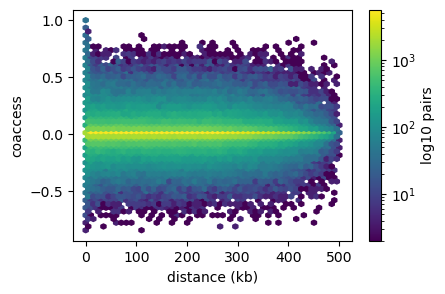

,Peak1,Peak2,coaccess
0,chr18_10006196_10006822,chr18_9755702_9755970,-0.077102
1,chr18_10006196_10006822,chr18_9756925_9757590,0.000000
2,chr18_10006196_10006822,chr18_9771216_9771842,0.018597
3,chr18_10006196_10006822,chr18_9781976_9782901,-0.084068
4,chr18_10006196_10006822,chr18_9784605_9785105,-0.007434


In [6]:
conns = epi.tl.assemble_connections(models)
print(conns.shape, "rows;", conns["coaccess"].isna().sum(), "NaN")
c = epi.tl.df_for_coords(conns["Peak1"].astype(str)); d = epi.tl.df_for_coords(conns["Peak2"].astype(str))
dist = np.abs((c.bp1 + c.bp2) / 2 - (d.bp1 + d.bp2) / 2)
plt.figure(figsize=(4.5, 3)); plt.hexbin(dist / 1e3, conns["coaccess"], gridsize=50, bins="log", cmap="viridis")
plt.xlabel("distance (kb)"); plt.ylabel("coaccess"); plt.colorbar(label="log10 pairs"); plt.show()
conns.head()

### `run_cicero` — the three steps in one call

```r
set.seed(42)
conns <- run_cicero(cicero_cds, sample_genome)   # window 500 kb, sample_num 100
```
`run_cicero` averages the distance parameters the way R's `mean()` does (long-double sum plus a
correction pass), which can differ from `np.mean` in the last bit; the step-by-step table above
used `np.mean`, hence differences at the 1e-16 level.

In [7]:
conns_rc = epi.tl.run_cicero(cicero, genome, random_state=42, n_jobs=8, silent=True)
print("mean distance parameter: run_cicero %r, np.mean %r" % (conns_rc.attrs["mean_distance_parameter"], mean_dp))
diff = np.nanmax(np.abs(conns_rc["coaccess"].to_numpy() - conns["coaccess"].to_numpy()))
print(f"max |difference| to the step-by-step table: {diff:.1e}")

mean distance parameter: run_cicero 0.6404942304943019, np.mean 0.640494230494302
max |difference| to the step-by-step table: 9.4e-16


A locus view: arcs between peaks with `coaccess > 0.25` in a 1 Mb region (height ∝ coaccess).

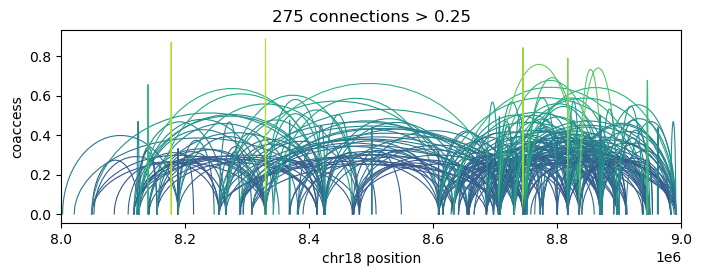

In [8]:
def arcs(conns, chrom, start, end, cutoff=0.25, ax=None):
    ax = ax or plt.gca()
    a = epi.tl.df_for_coords(conns["Peak1"].astype(str)); b = epi.tl.df_for_coords(conns["Peak2"].astype(str))
    x1 = (a.bp1 + a.bp2).to_numpy() / 2; x2 = (b.bp1 + b.bp2).to_numpy() / 2; co = conns["coaccess"].to_numpy()
    keep = (a.chr.to_numpy() == chrom) & (x1 < x2) & (x1 > start) & (x2 < end) & (co > cutoff)
    t = np.linspace(0, np.pi, 30)
    for u, v, h in zip(x1[keep], x2[keep], co[keep]):
        ax.plot((u + v) / 2 + (v - u) / 2 * np.cos(t), h * np.sin(t), color=plt.cm.viridis(h), lw=0.8)
    ax.set(xlim=(start, end), xlabel=f"{chrom} position", ylabel="coaccess"); return keep.sum()

plt.figure(figsize=(8, 2.5)); n = arcs(conns, "chr18", 8_000_000, 9_000_000); plt.title(f"{n} connections > 0.25"); plt.show()

### `generate_ccans` and `find_overlapping_ccans`

```r
ccan_assigns <- generate_ccans(conns)
```
Louvain communities of the graph of pairs above a cutoff; the cutoff is chosen by a bisection on
the number of CCANs, as in R. Louvain is randomised; the default `rng="R"` runs a port of
igraph's Louvain on R's random stream, so `random_state=42` returns the same table as
`set.seed(42); generate_ccans(conns)` in R. `rng="igraph"` uses python-igraph instead (faster on
very large graphs, same result only in distribution).

Coaccessibility cutoff used: 0.46


131 CCANs over 1393 peaks; cutoff 0.46
143 pairs of CCANs overlap in genomic span


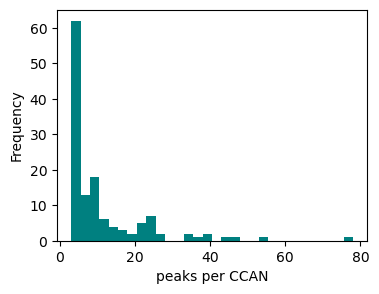

In [9]:
ccans = epi.tl.generate_ccans(conns, random_state=42)
print(ccans["CCAN"].nunique(), "CCANs over", len(ccans), "peaks; cutoff", ccans.attrs["coaccess_cutoff"])
ov = epi.tl.find_overlapping_ccans(ccans)
print(len(ov) // 2, "pairs of CCANs overlap in genomic span")
ccans["CCAN"].value_counts().plot.hist(bins=30, figsize=(4, 3), color="teal"); plt.xlabel("peaks per CCAN"); plt.show()

### Gene activity: `annotate_cds_by_site`, `build_gene_activity_matrix`, `normalize_gene_activities`

```r
input_cds <- annotate_cds_by_site(input_cds, gene_annotation_sub)
unnorm_ga <- build_gene_activity_matrix(input_cds, conns)
unnorm_ga <- unnorm_ga[!Matrix::rowSums(unnorm_ga) == 0, !Matrix::colSums(unnorm_ga) == 0]
cicero_gene_activities <- normalize_gene_activities(unnorm_ga, num_genes)
```
Promoter peaks carry a gene name; a gene's activity is its promoter accessibility plus the linked
distal accessibility weighted by co-accessibility. The promoter table is the one the Cicero
vignette builds from `gene_annotation_sample` (TSS ± 1 bp).

In [10]:
prom = pd.DataFrame({"chromosome": ref["prom_chromosome"], "start": ref["prom_start"],
                     "end": ref["prom_end"], "gene": ref["prom_gene"]})
atac_ann = atac.copy()
epi.tl.annotate_cds_by_site(atac_ann, prom)
print(atac_ann.var["gene"].notna().sum(), "promoter peaks")
ga = epi.tl.build_gene_activity_matrix(atac_ann, conns)
keep_c = np.asarray(ga.X.sum(1)).ravel() != 0; keep_g = np.asarray(ga.X.sum(0)).ravel() != 0
ga = ga[keep_c][:, keep_g].copy()
gn = epi.tl.normalize_gene_activities(ga, atac.obs["num_genes_expressed"])
top = pd.Series(np.asarray(gn.X.mean(0)).ravel(), index=gn.var_names).sort_values(ascending=False)
print(gn.shape); top.head(8)

974 promoter peaks


(200, 602)


TCF4      0.032295
TGIF1     0.018288
CEP192    0.017354
SMAD4     0.013298
SOGA2     0.012451
NEDD4L    0.010950
PTPRM     0.010646
CNDP2     0.010616
dtype: float64

### Utilities

```r
agg_cds <- aggregate_nearby_peaks(input_cds, distance = 10000)
find_overlapping_coordinates(peaks, "chr18:10,100-1246234")
compare_connections(conns, other_conns)
```

In [11]:
agg = epi.tl.aggregate_nearby_peaks(atac, distance=10000)
print("peaks merged within 10 kb:", atac.n_vars, "->", agg.n_vars)
hits = epi.tl.find_overlapping_coordinates(list(atac.var_names), "chr18:10,100-1246234")
print(len(hits), "peaks overlap chr18:10,100-1,246,234")
strong = conns[conns["coaccess"] > 0.5]
print("strong pairs also present in the full table:", epi.tl.compare_connections(strong.head(1000), conns).mean())

peaks merged within 10 kb: 6146 -> 1690
126 peaks overlap chr18:10,100-1,246,234


strong pairs also present in the full table: 1.0


### Export for CellOracle

CellOracle's base-GRN step reads a table with `Peak1`, `Peak2`, `coaccess` and peak ids
`chr_start_end`, plus the list of all peaks:

```python
# CellOracle tutorial (option 1: scATAC with Cicero)
cicero_connections = pd.read_csv("cicero_connections.csv", index_col=0)
integrated = ma.integrate(peaks=peaks, cicero_connections=cicero_connections)
```

In [12]:
import tempfile
out = Path(tempfile.mkdtemp(prefix="cicero_out_"))
co = epi.tl.cicero_connections_to_celloracle(conns, path=out / "cicero_connections.csv")
pd.DataFrame({"x": atac.var_names}).to_csv(out / "all_peaks.csv")
co.head()

,Peak1,Peak2,coaccess
0,chr18_10006196_10006822,chr18_9755702_9755970,-0.077102
1,chr18_10006196_10006822,chr18_9756925_9757590,0.000000
2,chr18_10006196_10006822,chr18_9771216_9771842,0.018597
3,chr18_10006196_10006822,chr18_9781976_9782901,-0.084068
4,chr18_10006196_10006822,chr18_9784605_9785105,-0.007434


## Part 2 — E8.5 heart multiome, chromosome 19

16,787 nuclei (10x multiome, mouse E8.5 heart region). Peaks are binarised as in the Cicero
vignette, and cells are aggregated on the RNA-derived UMAP of the same nuclei. The parity gates
F2 ran on exactly this input; R needs about 17 minutes for `make_cicero_cds` + `run_cicero` here,
the port about 15 s with 8 threads. Set `EPIONE_CICERO_E85` to the export directory to run it.

(16787, 8927) -> (3235, 8927) | 19 s | 1240298 rows


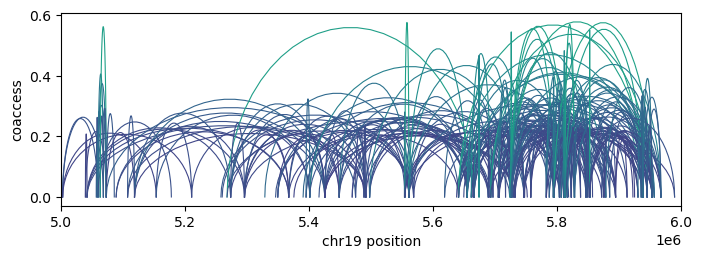

In [13]:
E85 = os.environ.get("EPIONE_CICERO_E85")
if E85 and Path(E85, "atac_counts.h5ad").exists():
    a = ad.read_h5ad(Path(E85, "atac_counts.h5ad"))
    a.var_names = a.var_names.str.replace(r"^(.*)[-:_](\d+)[-:_](\d+)$", r"\1_\2_\3", regex=True)
    a = a[:, a.var_names.str.startswith("chr19_")].copy()
    a.X = (a.X > 0).astype(np.float64)
    a = a[:, np.asarray(a.X.sum(0)).ravel() > 0].copy()
    umap = pd.read_csv(Path(E85, "emb_umap.harmony.rna.csv"), index_col=0)
    t0 = time.perf_counter()
    cc = epi.tl.make_cicero_cds(a, reduced_coordinates=umap, random_state=42, silent=True)
    e85 = epi.tl.run_cicero(cc, {"chr19": 61431566}, random_state=42, n_jobs=8, silent=True)
    print(a.shape, "->", cc.shape, f"| {time.perf_counter() - t0:.0f} s |", len(e85), "rows")
    plt.figure(figsize=(8, 2.5)); arcs(e85, "chr19", 5_000_000, 6_000_000, cutoff=0.2); plt.show()
else:
    print("EPIONE_CICERO_E85 not set: skipped")

## Pitfalls

- **Orientation.** R's CDS is peaks × cells; here cells are rows. `build_gene_activity_matrix`
  returns cells × genes (R: genes × cells).
- **Binarise first** if you follow the vignette (`make_atac_cds(binarize = TRUE)`); Cicero itself
  sums whatever is in `X`.
- **Random numbers.** `random_state=s` equals `set.seed(s)` right before the R function. To mimic
  one `set.seed()` for a whole R script, create `epi.tl._rrng.RRandom(s)` once and pass the same
  object to `make_cicero_cds`, `run_cicero` and `generate_ccans`. `rng="numpy"` (aggregation,
  windows) and `rng="igraph"` (Louvain) give results that agree with R only in distribution.
- **Peak order.** glasso visits the sites of a window in the order of `adata.var`, and with
  `thr = 1e-4` the result depends (slightly) on that order. Sort peaks by position — as
  `make_atac_cds` does — to reproduce R.
- **`genomic_coords`** must list every chromosome you want scanned; windows run from position 1
  to the chromosome length. Chromosome names are matched with `"chr"` stripped, as in R.
- **Sort order of names** (gene-activity genes, merged peaks, groups) follows R in an
  en_US.UTF-8 session; data.table output (`assemble_connections`) is in byte order.
- **Threads.** `n_jobs` changes speed only; outputs are identical for any value.

## Where to go next

- Parity report: `tests/parity/cicero/RECONSTRUCTION_REPORT.md`; gates: `MANIFEST.md`.
- R package: https://github.com/cole-trapnell-lab/cicero-release/tree/monocle3
- Pliner H. A. *et al.* Cicero predicts cis-regulatory DNA interactions from single-cell chromatin
  accessibility data. *Mol. Cell* 71, 858–871 (2018).
- Friedman J., Hastie T., Tibshirani R. Sparse inverse covariance estimation with the graphical
  lasso. *Biostatistics* 9, 432–441 (2008).